In [4]:
import os 
import sys
import pandas as pd
import seaborn as sns 
os.chdir("/Users/berial/ljy/lailab2025/pby_med12/MNase/new/")
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42  # 使 PDF 中字体可编辑
matplotlib.rcParams['ps.fonttype'] = 42
plt.rcParams["font.family"] = "Arial"

In [5]:
med12 = pd.read_table("med12tss_to_plus1_peak.bed", header=None)
med12_bed = med12.copy()
med12_bed.columns = ['chrom', 'start', 'end', 'name', 'score', 'strand']
med12['length'] = med12[2] - med12[1]
med12.rename(columns={3:'name'}, inplace=True)
med12 = med12[['name', 'length']]
med12_bed

,chrom,start,end,name,score,strand
0,chr1,8423577,8423832,NM_001042682.2,.,-
1,chr1,8817561,8817640,NM_012102.4,.,-
2,chr1,83998971,83999132,NM_001350214.2,.,-
3,chr1,117367448,117367705,NM_006699.5,.,+
4,chr1,167721981,167722027,NM_001146191.2,.,+
...,...,...,...,...,...,...
10413,chr22,50530003,50530085,NM_001257988.1,.,-
10414,chr22,50562715,50562919,NM_001123225.3,.,-
10415,chr22,50582769,50582849,NM_005198.5,.,-
10416,chr22,50627997,50628152,NM_000487.6,.,-


In [6]:
spt6 = pd.read_table("spt6tss_to_plus1_peak.bed", header=None)
spt6_bed = spt6.copy()
spt6_bed.columns = ['chrom', 'start', 'end', 'name', 'score', 'strand']
spt6['length'] = spt6[2] - spt6[1]
spt6.rename(columns={3:'name'}, inplace=True)
spt6 = spt6[['name', 'length']]
spt6_bed

,chrom,start,end,name,score,strand
0,chr1,8423608,8423832,NM_001042682.2,.,-
1,chr1,8817568,8817640,NM_012102.4,.,-
2,chr1,83999043,83999132,NM_001350214.2,.,-
3,chr1,117367448,117367541,NM_006699.5,.,+
4,chr1,167721981,167722019,NM_001146191.2,.,+
...,...,...,...,...,...,...
10420,chr22,50529920,50530085,NM_001257988.1,.,-
10421,chr22,50562824,50562919,NM_001123225.3,.,-
10422,chr22,50582693,50582849,NM_005198.5,.,-
10423,chr22,50628062,50628152,NM_000487.6,.,-


In [7]:
df = med12.merge(spt6, on='name')
df

,name,length_x,length_y
0,NM_001042682.2,255,224
1,NM_012102.4,79,72
2,NM_001350214.2,161,89
3,NM_006699.5,257,93
4,NM_001146191.2,46,38
...,...,...,...
10410,NM_001257988.1,82,165
10411,NM_001123225.3,204,95
10412,NM_005198.5,80,156
10413,NM_000487.6,155,90


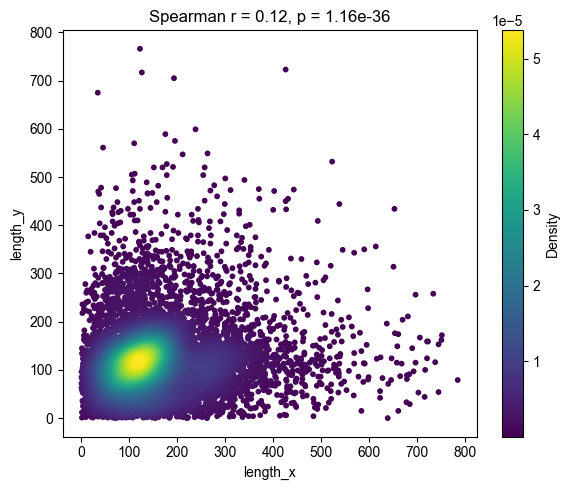

In [8]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from scipy.stats import gaussian_kde

# 示例数据（可替换为 df['length_x'], df['length_y']）
x = df['length_x']
y = df['length_y']

# 计算相关性
corr, pval = spearmanr(x, y)

# 计算密度用于颜色
xy = np.vstack([x, y])
z = gaussian_kde(xy)(xy)

# 按密度排序（高密度画在上层）
idx = z.argsort()
x_plot, y_plot, z_plot = x.values[idx], y.values[idx], z[idx]

# 绘图
plt.figure(figsize=(6, 5))
sc = plt.scatter(x_plot, y_plot, c=z_plot, cmap='viridis', s=10)
plt.colorbar(sc, label='Density')
plt.xlabel('length_x')
plt.ylabel('length_y')
plt.title(f"Spearman r = {corr:.2f}, p = {pval:.2e}")
# sns.regplot(x=x, y=y, scatter=False, color='red', line_kws={'linewidth': 1.2})
plt.tight_layout()
plt.savefig("p1tss_distance_densityscatterplot.pdf")
plt.show()


In [ ]:
# Q1 (smallest difference) is stable; Q4 (largest difference) is unstable.
df['length_difference'] = (df['length_x'] - df['length_y']).abs()
df['category'] = pd.qcut(
    df['length_difference'],
    q=4,
    labels=['Q1: Smallest Diff', 'Q2: Small Diff', 'Q3: Medium Diff', 'Q4: Largest Diff']
)

print("\nDataFrame with difference quantiles (first 5 rows):")
print(df.head())
print("-" * 30)
print("\nCounts by category:")
print(df['category'].value_counts().sort_index())


In [ ]:
# Set plot style
sns.set_style("whitegrid")
plt.figure(figsize=(5, 4))
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42  # Keep PDF text editable
matplotlib.rcParams['ps.fonttype'] = 42
plt.rcParams["font.family"] = "Arial"

# Q1 is stable (orange), Q4 is unstable (blue), and Q2/Q3 are transition colors.
scatterplot = sns.scatterplot(
    data=df,
    x='length_x',
    y='length_y',
    hue='category',
    hue_order=['Q1: Smallest Diff', 'Q2: Small Diff', 'Q3: Medium Diff', 'Q4: Largest Diff'],
    palette={
        'Q1: Smallest Diff': '#F39800',
        'Q2: Small Diff': '#F9C876',
        'Q3: Medium Diff': '#7CAAC6',
        'Q4: Largest Diff': '#2171a9',
    },
    s=10,
    alpha=1,
    edgecolor=None
)

# Add the diagonal y=x as a perfect-match reference.
min_val = min(df['length_x'].min(), df['length_y'].min())
max_val = max(df['length_x'].max(), df['length_y'].max())
plt.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.8, label='y = x (Perfect Match)')

plt.title('Distribution of Lengths by Difference Quantile Category')
plt.xlabel('Length X')
plt.ylabel('Length Y')
plt.legend(title='Difference Category')
plt.grid(False)
plt.tight_layout()
plt.savefig("p1tss_distance_scatterplot.pdf")
plt.show()


In [11]:
import pandas as pd


df['quartile'] = pd.qcut(df['length_difference'], 2, labels=['Q1', 'Q2']) # , 'Q3', 'Q4'])


# 3. 合并 df 与 med12_bed，按 name 匹配
merged = pd.merge(med12_bed, df[['name', 'quartile']], on='name', how='inner')

# 4. 拆分并输出为 4 个 BED 文件
for q in ['Q1', 'Q2']: #, 'Q3', 'Q4']:
    subset = merged[merged['quartile'] == q]
    bed_cols = ['chrom', 'start', 'end', 'name', 'score', 'strand']
    subset[bed_cols].to_csv(f"med12_{q}.bed", sep='\t', header=False, index=False)
    print(f"Saved {len(subset)} entries to med12_{q}.bed")


Saved 5253 entries to med12_Q1.bed
Saved 5162 entries to med12_Q2.bed


In [12]:
import pandas as pd


df['quartile'] = pd.qcut(df['length_difference'], 2, labels=['Q1', 'Q2']) # , 'Q3', 'Q4'])


# 3. 合并 df 与 spt6_bed，按 name 匹配
merged = pd.merge(spt6_bed, df[['name', 'quartile']], on='name', how='inner')

# 4. 拆分并输出为 4 个 BED 文件
for q in ['Q1', 'Q2']: #, 'Q3', 'Q4']:
    subset = merged[merged['quartile'] == q]
    bed_cols = ['chrom', 'start', 'end', 'name', 'score', 'strand']
    subset[bed_cols].to_csv(f"spt6_{q}.bed", sep='\t', header=False, index=False)
    print(f"Saved {len(subset)} entries to spt6_{q}.bed")


Saved 5253 entries to spt6_Q1.bed
Saved 5162 entries to spt6_Q2.bed
